we are going to implement the Deutsch–Jozsa algorithm using Qiskit. The goal is to determine whether a hidden Boolean function is constant or balanced by using superposition, an oracle, and quantum interference before measuring the final result.

In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

In [3]:
n = 3

print(f"Number of input qubits: {n}")

Number of input qubits: 3


In [4]:
def constant_oracle(n):
    oracle = QuantumCircuit(n + 1)

    # Constant-zero function:
    # no operation is required on the output qubit

    return oracle

In [5]:
def balanced_oracle(n):
    oracle = QuantumCircuit(n + 1)

    for qubit in range(n):
        oracle.cx(qubit, n)

    return oracle

In [6]:
def deutsch_jozsa_circuit(oracle, n):
    circuit = QuantumCircuit(n + 1, n)

    # Prepare the output qubit in |1>
    circuit.x(n)

    # Put all qubits into superposition
    for qubit in range(n + 1):
        circuit.h(qubit)

    # Apply the oracle
    circuit.compose(oracle, inplace=True)

    # Apply Hadamard gates to the input qubits
    for qubit in range(n):
        circuit.h(qubit)

    # Measure only the input qubits
    circuit.measure(range(n), range(n))

    return circuit

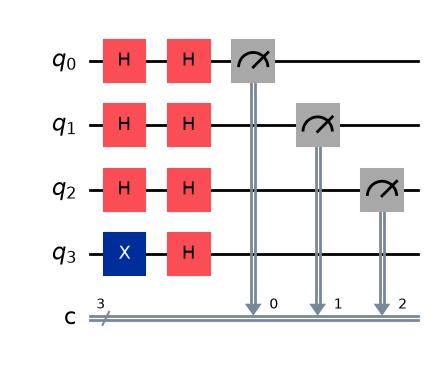

In [7]:
constant = constant_oracle(n)

constant_circuit = deutsch_jozsa_circuit(
    constant,
    n
)

constant_circuit.draw("mpl")

In [8]:
simulator = AerSimulator()

constant_result = simulator.run(
    constant_circuit,
    shots=1000
).result()

constant_counts = constant_result.get_counts()

print(constant_counts)

{'000': 1000}


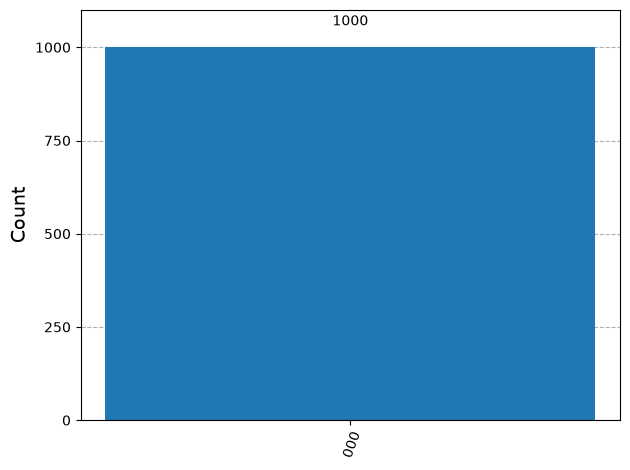

In [9]:
plot_histogram(constant_counts)

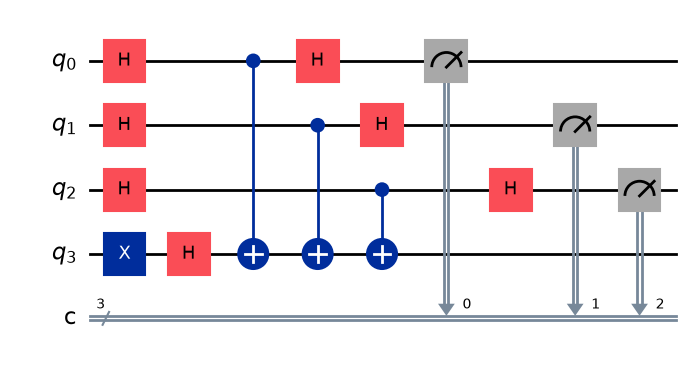

In [10]:
balanced = balanced_oracle(n)

balanced_circuit = deutsch_jozsa_circuit(
    balanced,
    n
)

balanced_circuit.draw("mpl")

In [11]:
balanced_result = simulator.run(
    balanced_circuit,
    shots=1000
).result()

balanced_counts = balanced_result.get_counts()

print(balanced_counts)

{'111': 1000}


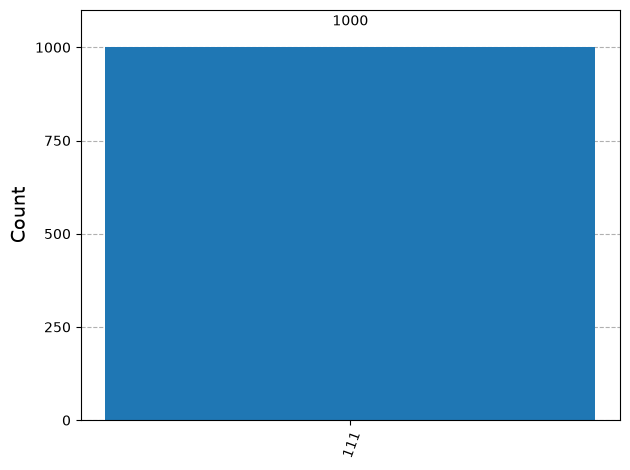

In [12]:
plot_histogram(balanced_counts)

In [13]:
def classify_result(counts, n):
    measured_state = max(counts, key=counts.get)

    if measured_state == "0" * n:
        return "Constant"
    else:
        return "Balanced"

In [14]:
print(
    "Constant oracle classification:",
    classify_result(constant_counts, n)
)

print(
    "Balanced oracle classification:",
    classify_result(balanced_counts, n)
)

Constant oracle classification: Constant
Balanced oracle classification: Balanced


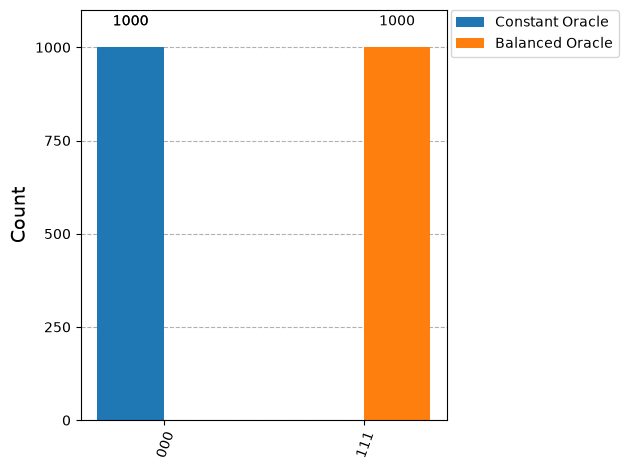

In [16]:
plot_histogram(
    [constant_counts, balanced_counts],
    legend=["Constant Oracle", "Balanced Oracle"]
)